Step 1: Checking OpenCV version and CascadeClassifier Available

In [ ]:
import cv2

print("OpenCV version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

OpenCV version: 5.0.0
CascadeClassifier available: False


In [ ]:
!pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless
!pip install -q opencv-python==4.10.0.84

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 MB 15.5 MB/s eta 0:00:00


In [ ]:
import cv2

print("OpenCV version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

OpenCV version: 4.10.0
CascadeClassifier available: True


Step 2: Importing Libraries

In [ ]:
!pip install opencv-python
!pip install tensorflow
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.20.0


Step 3: Uploading dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


Step 4: Extracting Dataset

In [ ]:
import zipfile
import os

zip_path = "/content/archive.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset extracted successfully!")
print("Folders in /content:", os.listdir("/content"))

Dataset extracted successfully!
Folders in /content: ['.config', 'faces', 'archive.zip', 'sample_data']


Step 5: Ckeck dataset Folders

In [ ]:
dataset_path = "/content/faces"

print("Dataset folders:")
print(os.listdir(dataset_path))

Dataset folders:
['man', 'woman']


Step 6: Dataset Images Load

In [ ]:
X = []
y = []

for label, folder in enumerate(["man", "woman"]):
    folder_path = os.path.join(dataset_path, folder)

    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)

        img = cv2.imread(image_path)

        if img is not None:
            img = cv2.resize(img, (64, 64))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            X.append(img)
            y.append(label)

X = np.array(X)
y = np.array(y)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Labels:", np.unique(y))

Images shape: (27167, 64, 64, 3)
Labels shape: (27167,)
Labels: [0 1]


Step 7: narmalize Pixel values

In [ ]:
X = X.astype("float32") / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())
print("Images shape:", X.shape)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Images shape: (27167, 64, 64, 3)


Step 8: Train and Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (21733, 64, 64, 3)
X_test shape: (5434, 64, 64, 3)
y_train shape: (21733,)
y_test shape: (5434,)


Step 9: CNN Model Build

In [ ]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(64, 64, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,329 (2.61 MB)

 Trainable params: 683,329 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

Step 10: CNN Compile

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


Step 11: CNN Training

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
544/544 ━━━━━━━━━━━━━━━━━━━━ 152s 274ms/step - accuracy: 0.7501 - loss: 0.4954 - val_accuracy: 0.8233 - val_loss: 0.3999
Epoch 2/10
544/544 ━━━━━━━━━━━━━━━━━━━━ 143s 263ms/step - accuracy: 0.8501 - loss: 0.3495 - val_accuracy: 0.8799 - val_loss: 0.2842
Epoch 3/10
544/544 ━━━━━━━━━━━━━━━━━━━━ 143s 262ms/step - accuracy: 0.8932 - loss: 0.2645 - val_accuracy: 0.8981 - val_loss: 0.2587
Epoch 4/10
544/544 ━━━━━━━━━━━━━━━━━━━━ 144s 265ms/step - accuracy: 0.9107 - loss: 0.2208 - val_accuracy: 0.9091 - val_loss: 0.2254
Epoch 5/10
544/544 ━━━━━━━━━━━━━━━━━━━━ 203s 267ms/step - accuracy: 0.9242 - loss: 0.1921 - val_accuracy: 0.9121 - val_loss: 0.2321
Epoch 6/10
544/544 ━━━━━━━━━━━━━━━━━━━━ 204s 271ms/step - accuracy: 0.9344 - loss: 0.1682 - val_accuracy: 0.9190 - val_loss: 0.2175
Epoch 7/10
544/544 ━━━━━━━━━━━━━━━━━━━━ 201s 269ms/step - accuracy: 0.9471 - loss: 0.1424 - val_accuracy: 0.9241 - val_loss: 0.2055
Epoch 8/10
544/544 ━━━━━━━━━━━━━━━━━━━━ 144s 264ms/step - accuracy: 0.9550 -

Step 12: Test Accuracy

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy Percentage:", test_accuracy * 100, "%")

170/170 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - accuracy: 0.9188 - loss: 0.2452
Test Loss: 0.24523770809173584
Test Accuracy: 0.9188443422317505
Test Accuracy Percentage: 91.88443422317505 %


Step 13: Confusion Matrix

170/170 ━━━━━━━━━━━━━━━━━━━━ 14s 80ms/step
Confusion Matrix:
[[3292  244]
 [ 197 1701]]


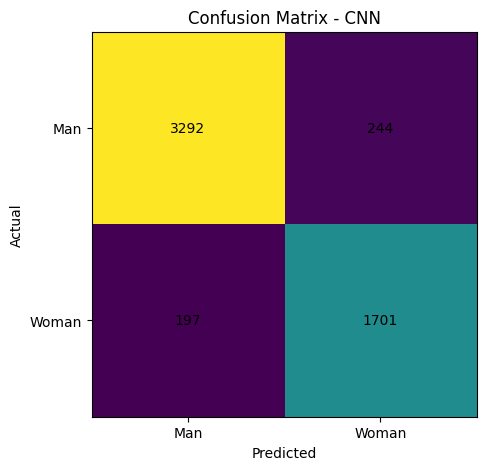

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Predict test data
y_pred_prob = model.predict(X_test, verbose=1)
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm)

plt.title("Confusion Matrix - CNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Man", "Woman"])
plt.yticks([0, 1], ["Man", "Woman"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

Step 14: Classification Report

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report - CNN")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Man", "Woman"]
    )
)

Classification Report - CNN
              precision    recall  f1-score   support

         Man       0.94      0.93      0.94      3536
       Woman       0.87      0.90      0.89      1898

    accuracy                           0.92      5434
   macro avg       0.91      0.91      0.91      5434
weighted avg       0.92      0.92      0.92      5434



Step 15: CNN Training and Validation Accuracy Graph

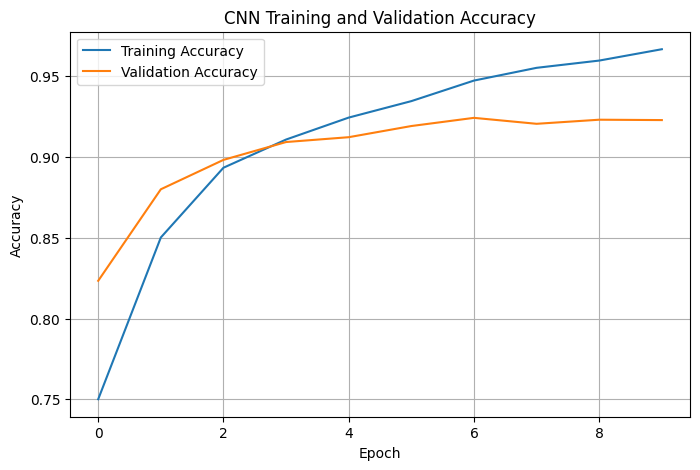

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

Step 16: CNN Training and Validation Loss Graph

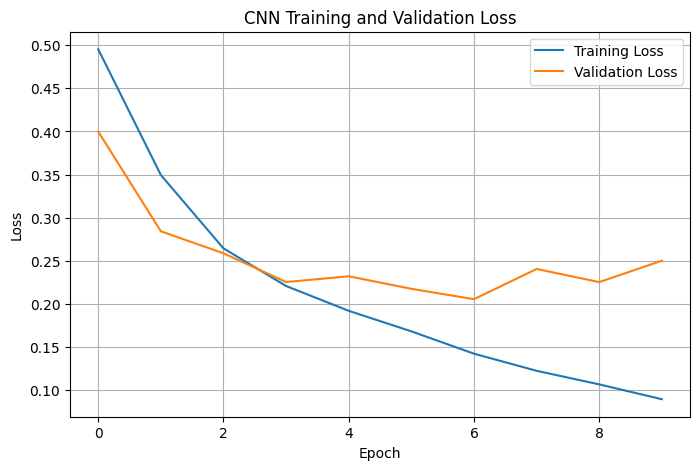

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
correct = np.sum(y_pred == y_test)
wrong = np.sum(y_pred != y_test)

print("Total Test Images:", len(y_test))
print("Correct Predictions:", correct)
print("Wrong Predictions:", wrong)
print("Accuracy:", (correct / len(y_test)) * 100, "%")

Total Test Images: 5434
Correct Predictions: 4993
Wrong Predictions: 441
Accuracy: 91.88443135811556 %


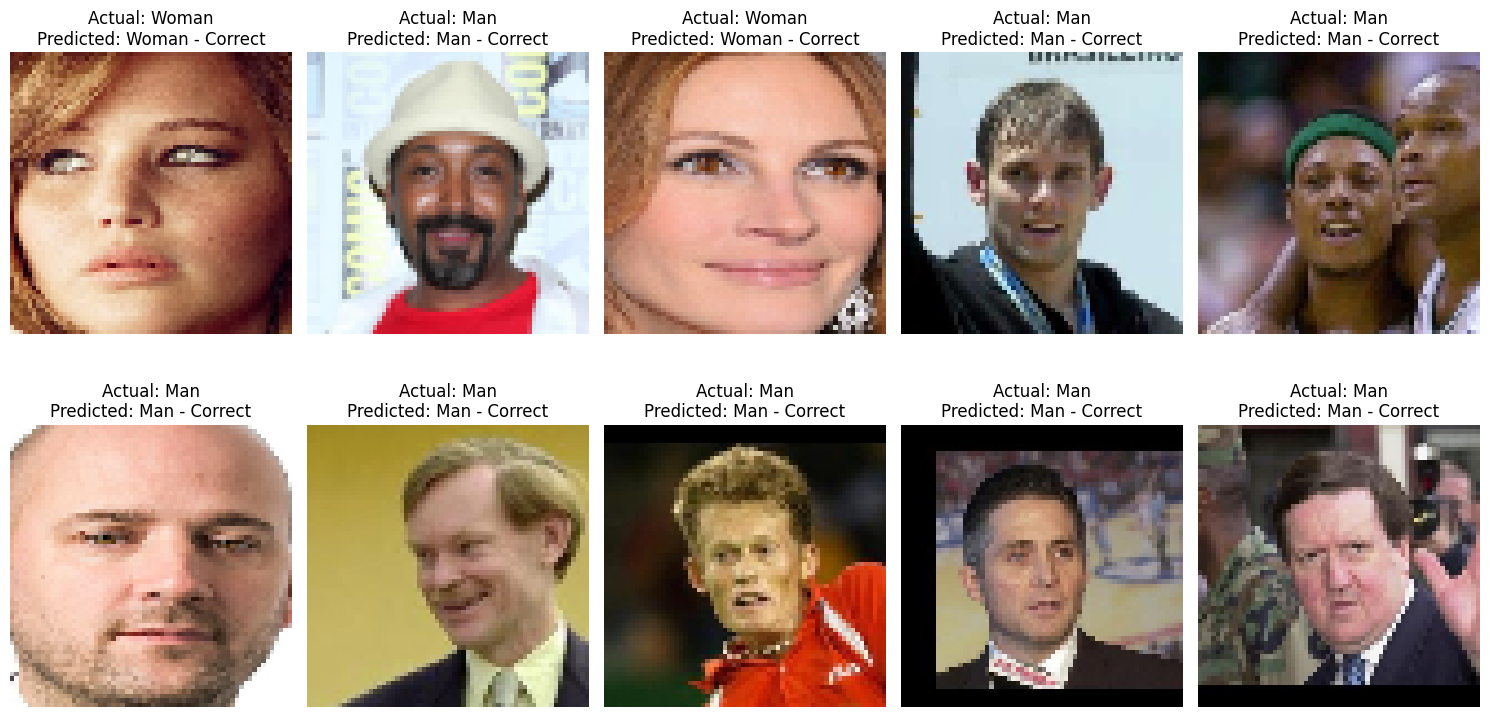

In [ ]:
import random

labels = ["Man", "Woman"]

indices = random.sample(range(len(X_test)), 10)

plt.figure(figsize=(15, 8))

for i, index in enumerate(indices):
    image = X_test[index]
    actual = y_test[index]
    predicted = y_pred[index]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)

    if actual == predicted:
        title = "Correct"
    else:
        title = "Wrong"

    plt.title(
        f"Actual: {labels[actual]}\n"
        f"Predicted: {labels[predicted]} - {title}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

Total wrong predictions: 441


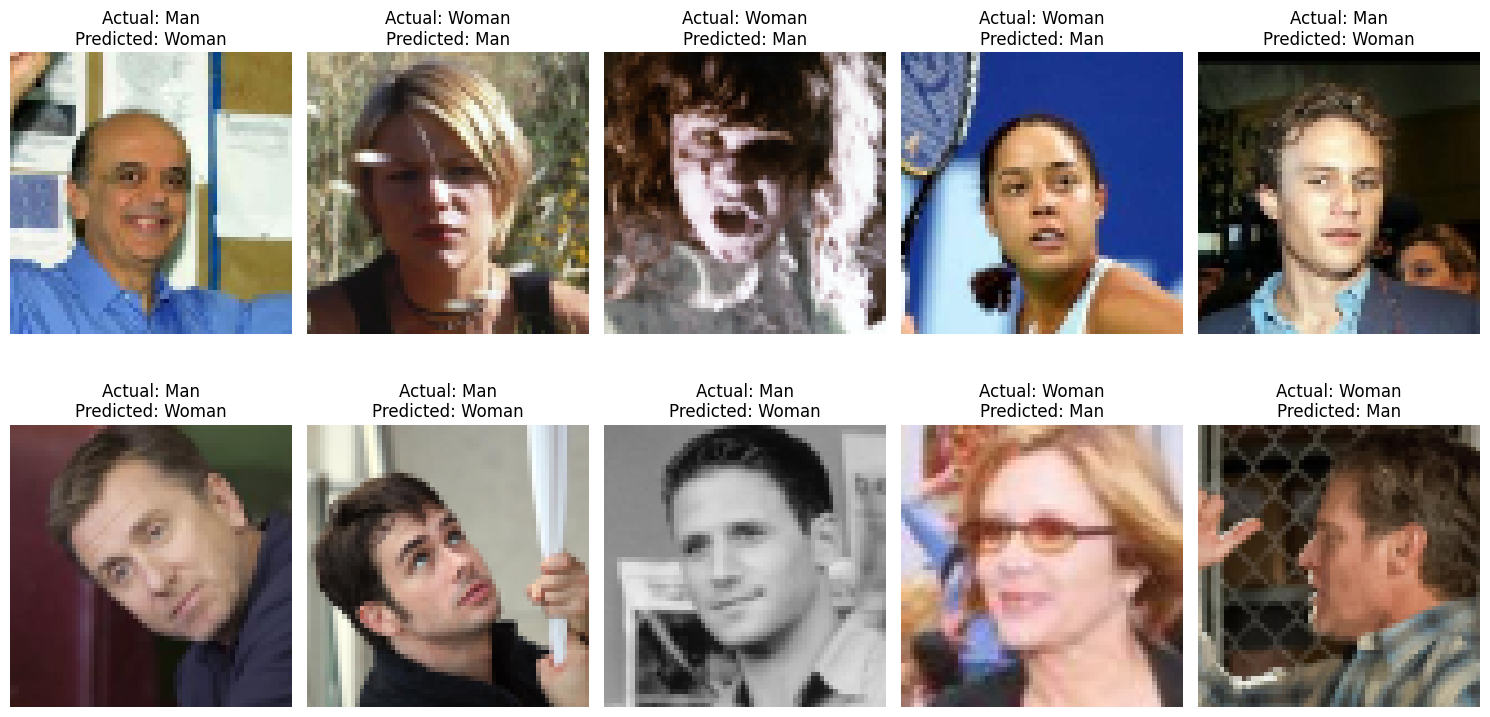

In [ ]:
wrong_indices = np.where(y_pred != y_test)[0]

print("Total wrong predictions:", len(wrong_indices))

plt.figure(figsize=(15, 8))

for i, index in enumerate(wrong_indices[:10]):
    image = X_test[index]
    actual = y_test[index]
    predicted = y_pred[index]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)

    plt.title(
        f"Actual: {labels[actual]}\n"
        f"Predicted: {labels[predicted]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

print("Face detector ready:", not face_cascade.empty())

Face detector ready: True


Saving WhatsApp Image 2026-09-09 at 4.56.30 PM.jpeg to WhatsApp Image 2026-09-09 at 4.56.30 PM (1).jpeg
Faces detected: 2
Prediction: Woman
Confidence: 99.95 %


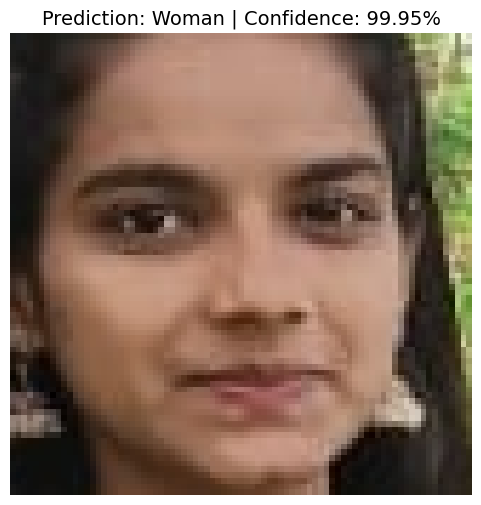

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Upload image from laptop
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    print("Image could not be loaded.")

else:
    # Detect faces
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    print("Faces detected:", len(faces))

    if len(faces) == 0:
        print("No face detected.")

    else:
        # Select largest face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        face = img[y:y+h, x:x+w]
        face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

        # Prepare for CNN
        face_64 = cv2.resize(face_rgb, (64, 64))
        face_input = face_64.astype("float32") / 255.0
        face_input = np.expand_dims(face_input, axis=0)

        # Prediction
        probability = float(model.predict(face_input, verbose=0)[0][0])

        if probability >= 0.5:
            prediction = "Woman"
            confidence = probability
        else:
            prediction = "Man"
            confidence = 1 - probability

        print("Prediction:", prediction)
        print("Confidence:", round(confidence * 100, 2), "%")

        # Display clear cropped face
        plt.figure(figsize=(6, 6))
        plt.imshow(face_rgb)
        plt.title(
            f"Prediction: {prediction} | "
            f"Confidence: {confidence * 100:.2f}%",
            fontsize=14
        )
        plt.axis("off")
        plt.show()

Saving WhatsApp Image 2026-09-09 at 4.57.17 PM.jpeg to WhatsApp Image 2026-09-09 at 4.57.17 PM (1).jpeg
Faces detected: 3
Prediction: Woman
Confidence: 99.87 %


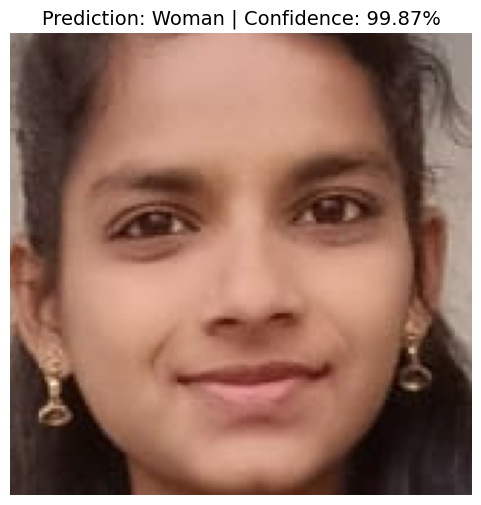

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Upload image from laptop
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    print("Image could not be loaded.")

else:
    # Detect faces
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    print("Faces detected:", len(faces))

    if len(faces) == 0:
        print("No face detected.")

    else:
        # Select largest face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        face = img[y:y+h, x:x+w]
        face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

        # Prepare for CNN
        face_64 = cv2.resize(face_rgb, (64, 64))
        face_input = face_64.astype("float32") / 255.0
        face_input = np.expand_dims(face_input, axis=0)

        # Prediction
        probability = float(model.predict(face_input, verbose=0)[0][0])

        if probability >= 0.5:
            prediction = "Woman"
            confidence = probability
        else:
            prediction = "Man"
            confidence = 1 - probability

        print("Prediction:", prediction)
        print("Confidence:", round(confidence * 100, 2), "%")

        # Display clear cropped face
        plt.figure(figsize=(6, 6))
        plt.imshow(face_rgb)
        plt.title(
            f"Prediction: {prediction} | "
            f"Confidence: {confidence * 100:.2f}%",
            fontsize=14
        )
        plt.axis("off")
        plt.show()

Saving Photo15.jpeg to Photo15.jpeg
Faces detected: 2
Prediction: Man
Confidence: 100.0 %


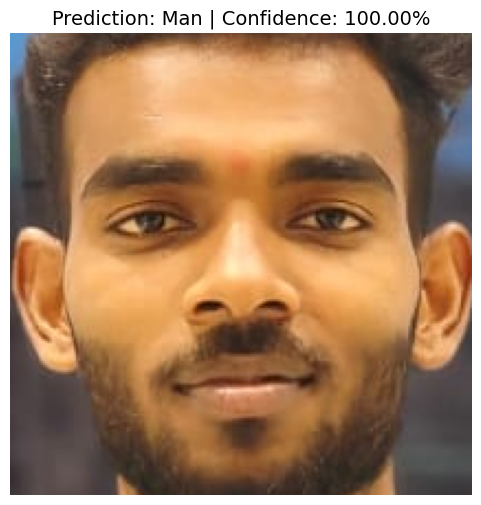

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Upload image from laptop
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    print("Image could not be loaded.")

else:
    # Detect faces
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    print("Faces detected:", len(faces))

    if len(faces) == 0:
        print("No face detected.")

    else:
        # Select largest face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        face = img[y:y+h, x:x+w]
        face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

        # Prepare for CNN
        face_64 = cv2.resize(face_rgb, (64, 64))
        face_input = face_64.astype("float32") / 255.0
        face_input = np.expand_dims(face_input, axis=0)

        # Prediction
        probability = float(model.predict(face_input, verbose=0)[0][0])

        if probability >= 0.5:
            prediction = "Woman"
            confidence = probability
        else:
            prediction = "Man"
            confidence = 1 - probability

        print("Prediction:", prediction)
        print("Confidence:", round(confidence * 100, 2), "%")

        # Display clear cropped face
        plt.figure(figsize=(6, 6))
        plt.imshow(face_rgb)
        plt.title(
            f"Prediction: {prediction} | "
            f"Confidence: {confidence * 100:.2f}%",
            fontsize=14
        )
        plt.axis("off")
        plt.show()

Saving passport size photo.jpeg to passport size photo.jpeg
Faces detected: 3
Prediction: Woman
Confidence: 92.13 %


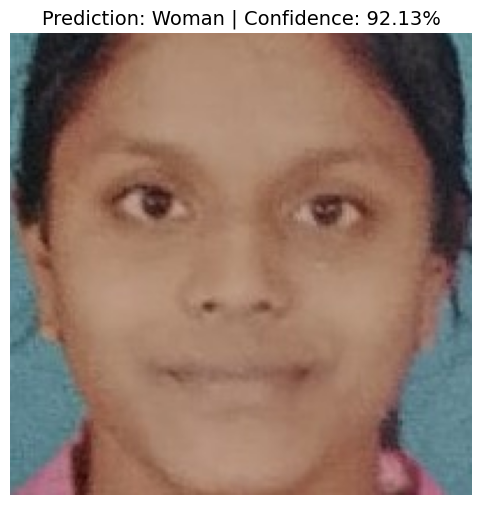

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Upload image from laptop
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    print("Image could not be loaded.")

else:
    # Detect faces
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    print("Faces detected:", len(faces))

    if len(faces) == 0:
        print("No face detected.")

    else:
        # Select largest face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        face = img[y:y+h, x:x+w]
        face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

        # Prepare for CNN
        face_64 = cv2.resize(face_rgb, (64, 64))
        face_input = face_64.astype("float32") / 255.0
        face_input = np.expand_dims(face_input, axis=0)

        # Prediction
        probability = float(model.predict(face_input, verbose=0)[0][0])

        if probability >= 0.5:
            prediction = "Woman"
            confidence = probability
        else:
            prediction = "Man"
            confidence = 1 - probability

        print("Prediction:", prediction)
        print("Confidence:", round(confidence * 100, 2), "%")

        # Display clear cropped face
        plt.figure(figsize=(6, 6))
        plt.imshow(face_rgb)
        plt.title(
            f"Prediction: {prediction} | "
            f"Confidence: {confidence * 100:.2f}%",
            fontsize=14
        )
        plt.axis("off")
        plt.show()

Saving Photo.jpg to Photo.jpg
Faces detected: 1
Prediction: Man
Confidence: 100.0 %


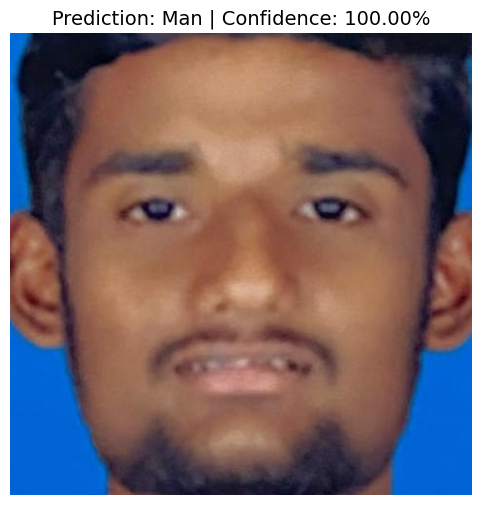

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Upload image from laptop
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    print("Image could not be loaded.")

else:
    # Detect faces
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    print("Faces detected:", len(faces))

    if len(faces) == 0:
        print("No face detected.")

    else:
        # Select largest face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        face = img[y:y+h, x:x+w]
        face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

        # Prepare for CNN
        face_64 = cv2.resize(face_rgb, (64, 64))
        face_input = face_64.astype("float32") / 255.0
        face_input = np.expand_dims(face_input, axis=0)

        # Prediction
        probability = float(model.predict(face_input, verbose=0)[0][0])

        if probability >= 0.5:
            prediction = "Woman"
            confidence = probability
        else:
            prediction = "Man"
            confidence = 1 - probability

        print("Prediction:", prediction)
        print("Confidence:", round(confidence * 100, 2), "%")

        # Display clear cropped face
        plt.figure(figsize=(6, 6))
        plt.imshow(face_rgb)
        plt.title(
            f"Prediction: {prediction} | "
            f"Confidence: {confidence * 100:.2f}%",
            fontsize=14
        )
        plt.axis("off")
        plt.show()

Saving ss.jpg to ss.jpg
Faces detected: 1
Prediction: Woman
Confidence: 98.78 %


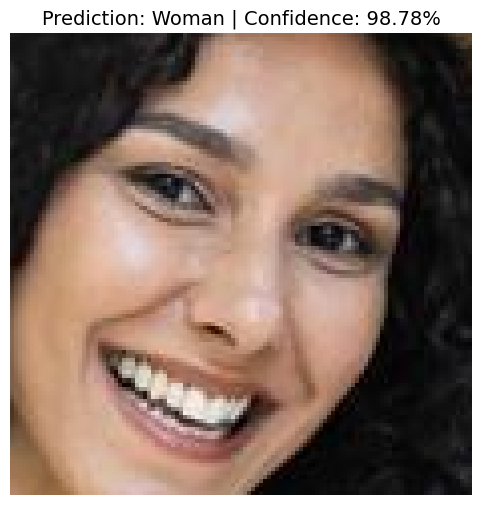

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Upload image from laptop
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    print("Image could not be loaded.")

else:
    # Detect faces
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    print("Faces detected:", len(faces))

    if len(faces) == 0:
        print("No face detected.")

    else:
        # Select largest face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        face = img[y:y+h, x:x+w]
        face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

        # Prepare for CNN
        face_64 = cv2.resize(face_rgb, (64, 64))
        face_input = face_64.astype("float32") / 255.0
        face_input = np.expand_dims(face_input, axis=0)

        # Prediction
        probability = float(model.predict(face_input, verbose=0)[0][0])

        if probability >= 0.5:
            prediction = "Woman"
            confidence = probability
        else:
            prediction = "Man"
            confidence = 1 - probability

        print("Prediction:", prediction)
        print("Confidence:", round(confidence * 100, 2), "%")

        # Display clear cropped face
        plt.figure(figsize=(6, 6))
        plt.imshow(face_rgb)
        plt.title(
            f"Prediction: {prediction} | "
            f"Confidence: {confidence * 100:.2f}%",
            fontsize=14
        )
        plt.axis("off")
        plt.show()

Saving mm.jpeg to mm.jpeg
Faces detected: 1
Prediction: Man
Confidence: 99.86 %


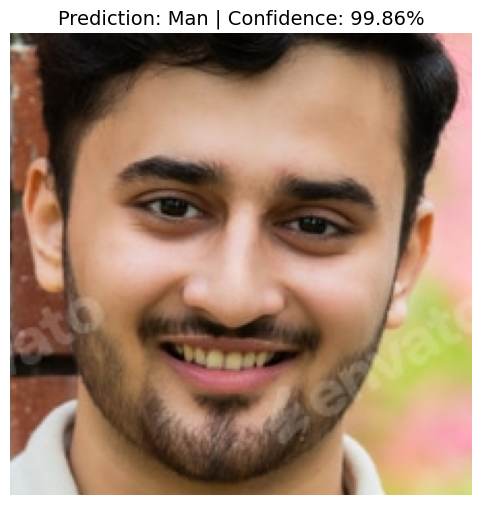

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Upload image from laptop
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    print("Image could not be loaded.")

else:
    # Detect faces
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    print("Faces detected:", len(faces))

    if len(faces) == 0:
        print("No face detected.")

    else:
        # Select largest face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        face = img[y:y+h, x:x+w]
        face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

        # Prepare for CNN
        face_64 = cv2.resize(face_rgb, (64, 64))
        face_input = face_64.astype("float32") / 255.0
        face_input = np.expand_dims(face_input, axis=0)

        # Prediction
        probability = float(model.predict(face_input, verbose=0)[0][0])

        if probability >= 0.5:
            prediction = "Woman"
            confidence = probability
        else:
            prediction = "Man"
            confidence = 1 - probability

        print("Prediction:", prediction)
        print("Confidence:", round(confidence * 100, 2), "%")

        # Display clear cropped face
        plt.figure(figsize=(6, 6))
        plt.imshow(face_rgb)
        plt.title(
            f"Prediction: {prediction} | "
            f"Confidence: {confidence * 100:.2f}%",
            fontsize=14
        )
        plt.axis("off")
        plt.show()

Saving ssss.jpg to ssss.jpg
Faces detected: 1
Prediction: Woman
Confidence: 100.0 %


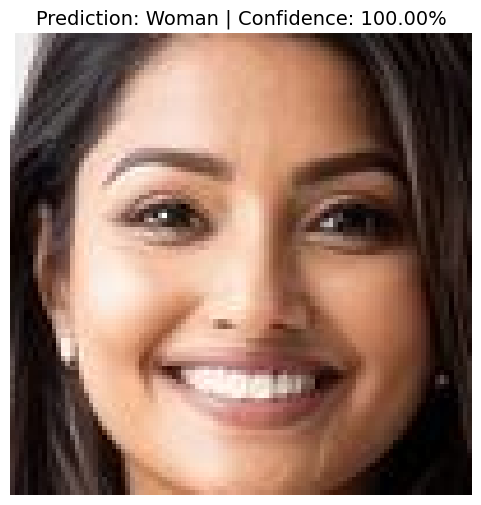

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Upload image from laptop
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    print("Image could not be loaded.")

else:
    # Detect faces
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    print("Faces detected:", len(faces))

    if len(faces) == 0:
        print("No face detected.")

    else:
        # Select largest face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        face = img[y:y+h, x:x+w]
        face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

        # Prepare for CNN
        face_64 = cv2.resize(face_rgb, (64, 64))
        face_input = face_64.astype("float32") / 255.0
        face_input = np.expand_dims(face_input, axis=0)

        # Prediction
        probability = float(model.predict(face_input, verbose=0)[0][0])

        if probability >= 0.5:
            prediction = "Woman"
            confidence = probability
        else:
            prediction = "Man"
            confidence = 1 - probability

        print("Prediction:", prediction)
        print("Confidence:", round(confidence * 100, 2), "%")

        # Display clear cropped face
        plt.figure(figsize=(6, 6))
        plt.imshow(face_rgb)
        plt.title(
            f"Prediction: {prediction} | "
            f"Confidence: {confidence * 100:.2f}%",
            fontsize=14
        )
        plt.axis("off")
        plt.show()

Saving mmmm.jpg to mmmm.jpg
Faces detected: 1
Prediction: Woman
Confidence: 93.56 %


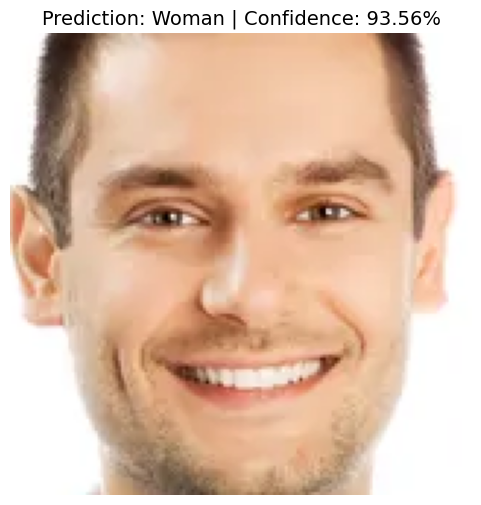

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Upload image from laptop
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    print("Image could not be loaded.")

else:
    # Detect faces
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    print("Faces detected:", len(faces))

    if len(faces) == 0:
        print("No face detected.")

    else:
        # Select largest face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        face = img[y:y+h, x:x+w]
        face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

        # Prepare for CNN
        face_64 = cv2.resize(face_rgb, (64, 64))
        face_input = face_64.astype("float32") / 255.0
        face_input = np.expand_dims(face_input, axis=0)

        # Prediction
        probability = float(model.predict(face_input, verbose=0)[0][0])

        if probability >= 0.5:
            prediction = "Woman"
            confidence = probability
        else:
            prediction = "Man"
            confidence = 1 - probability

        print("Prediction:", prediction)
        print("Confidence:", round(confidence * 100, 2), "%")

        # Display clear cropped face
        plt.figure(figsize=(6, 6))
        plt.imshow(face_rgb)
        plt.title(
            f"Prediction: {prediction} | "
            f"Confidence: {confidence * 100:.2f}%",
            fontsize=14
        )
        plt.axis("off")
        plt.show()

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Upload image from laptop
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    print("Image could not be loaded.")

else:
    # Detect faces
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    print("Faces detected:", len(faces))

    if len(faces) == 0:
        print("No face detected.")

    else:
        # Select largest face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        face = img[y:y+h, x:x+w]
        face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

        # Prepare for CNN
        face_64 = cv2.resize(face_rgb, (64, 64))
        face_input = face_64.astype("float32") / 255.0
        face_input = np.expand_dims(face_input, axis=0)

        # Prediction
        probability = float(model.predict(face_input, verbose=0)[0][0])

        if probability >= 0.5:
            prediction = "Woman"
            confidence = probability
        else:
            prediction = "Man"
            confidence = 1 - probability

        print("Prediction:", prediction)
        print("Confidence:", round(confidence * 100, 2), "%")

        # Display clear cropped face
        plt.figure(figsize=(6, 6))
        plt.imshow(face_rgb)
        plt.title(
            f"Prediction: {prediction} | "
            f"Confidence: {confidence * 100:.2f}%",
            fontsize=14
        )
        plt.axis("off")
        plt.show()

Saving dog1.jpg to dog1.jpg
Faces detected: 0
No face detected.


In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Upload image from laptop
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    print("Image could not be loaded.")

else:
    # Detect faces
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    print("Faces detected:", len(faces))

    if len(faces) == 0:
        print("No face detected.")

    else:
        # Select largest face
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

        face = img[y:y+h, x:x+w]
        face_rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

        # Prepare for CNN
        face_64 = cv2.resize(face_rgb, (64, 64))
        face_input = face_64.astype("float32") / 255.0
        face_input = np.expand_dims(face_input, axis=0)

        # Prediction
        probability = float(model.predict(face_input, verbose=0)[0][0])

        if probability >= 0.5:
            prediction = "Woman"
            confidence = probability
        else:
            prediction = "Man"
            confidence = 1 - probability

        print("Prediction:", prediction)
        print("Confidence:", round(confidence * 100, 2), "%")

        # Display clear cropped face
        plt.figure(figsize=(6, 6))
        plt.imshow(face_rgb)
        plt.title(
            f"Prediction: {prediction} | "
            f"Confidence: {confidence * 100:.2f}%",
            fontsize=14
        )
        plt.axis("off")
        plt.show()

Saving truck.png to truck.png
Faces detected: 0
No face detected.
